# Do the halo results depend on the profile?

The main results use a smoothed top hat. Here the two halo effects are repeated for shapes taken from simulations and observations:

- **NFW-like** — the cuspy form predicted by cold-dark-matter simulations, regularised with a small inner core so the centre is finite. A true NFW diverges as $1/r$, though its enclosed mass, and hence the field, stay regular.
- **cored (Burkert)** — the flat-centred shape that better fits dwarf-galaxy rotation curves.

The difference that matters is whether the profile has a flat centre for the field to pin to. Where it does, screening survives until a threshold in $\beta$; where it does not, it degrades from the start — so the idealised top hat turns out to be the *conservative* choice.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath(os.path.join('..', '..', 'main')))

import numpy as np
import matplotlib.pyplot as plt

import styling
import mixed_screening as ms
import robustness_sweep as sweep

styling.apply()

In [2]:
def load(path, runner, label):
    if os.path.exists(path):
        d = np.load(path)
        if 'complete' in d.files and bool(d['complete']):
            print(f'{label}: loaded cache'); return d
        print(f'{label}: cache incomplete -- recomputing')
    runner()
    return np.load(path)

d = load(sweep.OUT_HALO, sweep.run_halo, 'halo robustness')
rho_ins, betas = d['rho_ins'], d['betas']
AT = float(d['at'])
names = ['top-hat', 'NFW-like', 'cored']
RED = {n: d[f'RED_{n}'] for n in names}
DSC = {n: d[f'DSC_{n}'] for n in names}

print(f'geometric ceiling at^(-2/3) = {AT**(-2/3):.4f}\n')
print(f"{'profile':10s}  reduction at lowest/highest density   D at lowest/highest beta")
for n in names:
    print(f'{n:10s}  {RED[n][0]:.4f} -> {RED[n][-1]:.4f}'
          f'                    {DSC[n][0]:.4f} -> {DSC[n][-1]:.4f}')

halo robustness: loaded cache
geometric ceiling at^(-2/3) = 0.5429

profile     reduction at lowest/highest density   D at lowest/highest beta
top-hat     0.5345 -> 0.1370                    0.0000 -> 0.1868
NFW-like    0.5404 -> 0.2695                    0.1447 -> 0.7430
cored       0.5342 -> 0.1532                    0.0000 -> 0.2095


## Figure

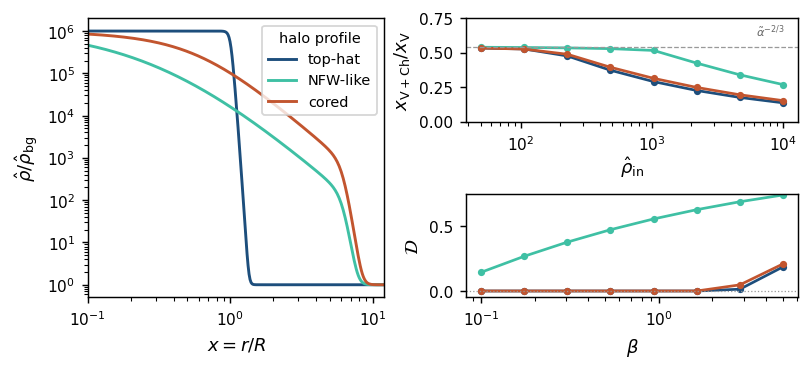

In [3]:
C = styling.PROFILES

fig = plt.figure(figsize=(styling.WIDE, styling.COL * 0.82))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.12], hspace=0.7, wspace=0.26)
axP = fig.add_subplot(gs[:, 0])
axR = fig.add_subplot(gs[0, 1])
axD = fig.add_subplot(gs[1, 1])

# ---- the profiles themselves ----
xp = np.logspace(-1, 1.1, 300)
for nm, dens in sweep.halo_profiles(sweep.H_IN_DSC).items():
    axP.plot(xp, dens(xp) / sweep.H_BG, color=C[nm], lw=1.6, label=nm)
axP.set_xscale('log'); axP.set_yscale('log'); axP.set_xlim(0.1, 12)
axP.set_xlabel(r'$x=r/R$'); axP.set_ylabel(r'$\hat\rho/\hat\rho_{\rm bg}$')
axP.legend(fontsize=8, loc='upper right', title='halo profile', title_fontsize=8)

# ---- Vainshtein-radius reduction against density ----
for nm in names:
    axR.plot(rho_ins, RED[nm], 'o-', color=C[nm], lw=1.5, ms=3)
axR.axhline(AT**(-2 / 3), color='0.6', lw=0.7, ls='--')
axR.set_xscale('log'); axR.set_ylim(0, 0.75)
axR.set_xlabel(r'$\hat\rho_{\rm in}$', labelpad=1)
axR.set_ylabel(r'$x_{\rm V+Ch}/x_{\rm V}$')
axR.text(0.96, 0.8, r'$\tilde\alpha^{-2/3}$', transform=axR.transAxes,
         ha='right', va='bottom', fontsize=6.3, color='0.4')

# ---- core de-screening against Vainshtein strength ----
for nm in names:
    axD.plot(betas, DSC[nm], 'o-', color=C[nm], lw=1.5, ms=3)
axD.axhline(0, color='0.6', lw=0.7, ls=':')
axD.set_xscale('log'); axD.set_ylim(-0.05, 0.75)
axD.set_xlabel(r'$\beta$'); axD.set_ylabel(r'$\mathcal{D}$')

fig.savefig('robustness_halo.png', dpi=200, bbox_inches='tight')
plt.show()